# Taller Final Minería de Datos: Segmentación de Clientes con K-Means

**Dataset:** [Mall Customers Dataset (Kaggle)](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)

**Objetivo general:** desarrollar un modelo de segmentación de clientes con el algoritmo K-Means, evaluarlo con el método del codo y el coeficiente de silueta, y analizar los patrones de comportamiento para apoyar decisiones de marketing.

### ¿Cómo funciona K-Means?
1. Se eligen **K** centroides iniciales (aquí con `k-means++`, que los separa entre sí para converger mejor).
2. Cada observación se asigna al centroide más cercano (distancia euclidiana).
3. Cada centroide se recalcula como la media de los puntos asignados.
4. Se repiten los pasos 2 y 3 hasta que las asignaciones dejan de cambiar.

El algoritmo minimiza la **inercia (WCSS)**, la suma de distancias al cuadrado de cada punto a su centroide.

In [1]:
# Ejecutar solo si faltan librerías
# !pip install -r requirements.txt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

sns.set_theme(style="whitegrid")

## Parte 1 – Exploración de Datos
### 1.1 Cargar el dataset

In [2]:
df = pd.read_csv('Mall_Customers.csv')
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


### 1.2 Identificar variables relevantes

| Variable | Tipo | ¿Útil para segmentar? |
|---|---|---|
| `CustomerID` | Identificador | No, es solo un consecutivo sin significado. |
| `Gender` | Categórica | Poco. K-Means usa distancias euclidianas y una variable binaria no aporta estructura de grupos. |
| `Age` | Numérica | Sirve como variable descriptiva para perfilar los grupos. |
| `Annual Income (k$)` | Numérica | **Sí**, es la capacidad de compra. |
| `Spending Score (1-100)` | Numérica | **Sí**, es el comportamiento de gasto. |

### 1.3 Análisis descriptivo básico

In [4]:
print("--- Estadísticas descriptivas ---")
display(df.describe().round(2))
print("--- Valores nulos ---")
print(df.isnull().sum())
print("\n--- Duplicados:", df.duplicated().sum())
print("\n--- Distribución por género ---")
print(df['Gender'].value_counts())

--- Estadísticas descriptivas ---


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


--- Valores nulos ---
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

--- Duplicados: 0

--- Distribución por género ---
Gender
Female    112
Male       88
Name: count, dtype: int64


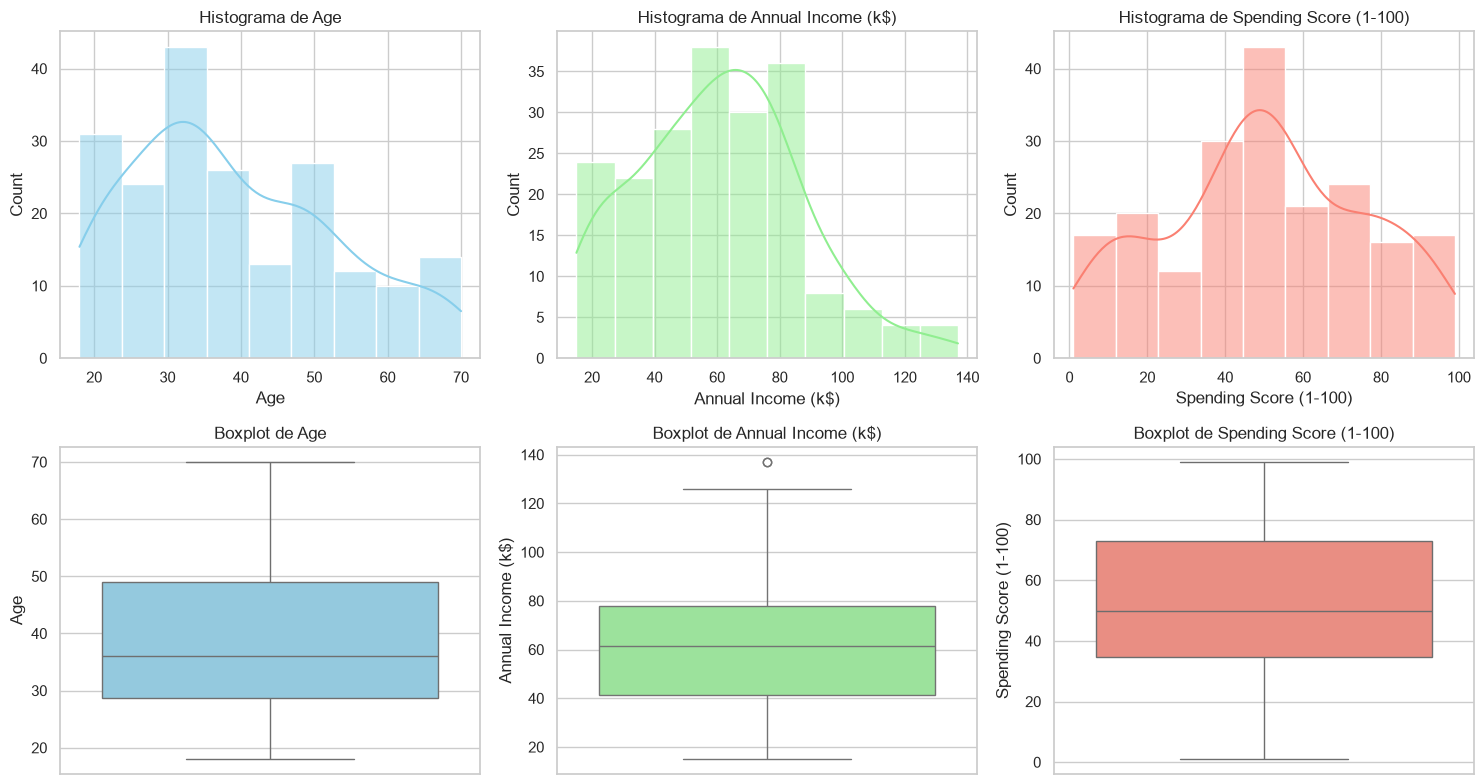

In [5]:
num_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
colores = ['skyblue', 'lightgreen', 'salmon']
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color=colores[i])
    axes[0, i].set_title(f'Histograma de {col}')
    sns.boxplot(data=df, y=col, ax=axes[1, i], color=colores[i])
    axes[1, i].set_title(f'Boxplot de {col}')
plt.tight_layout()
plt.show()

In [6]:
# Detección de valores atípicos con el criterio IQR (1.5 * rango intercuartílico)
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col}: límites [{lim_inf:.1f}, {lim_sup:.1f}] -> {len(atipicos)} atípicos {atipicos[col].tolist()}")

Age: límites [-1.6, 79.4] -> 0 atípicos []
Annual Income (k$): límites [-13.2, 132.8] -> 2 atípicos [137, 137]
Spending Score (1-100): límites [-22.6, 130.4] -> 0 atípicos []


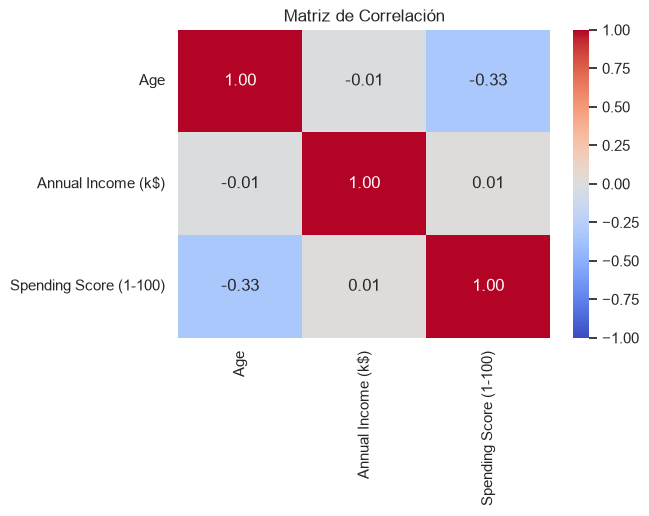

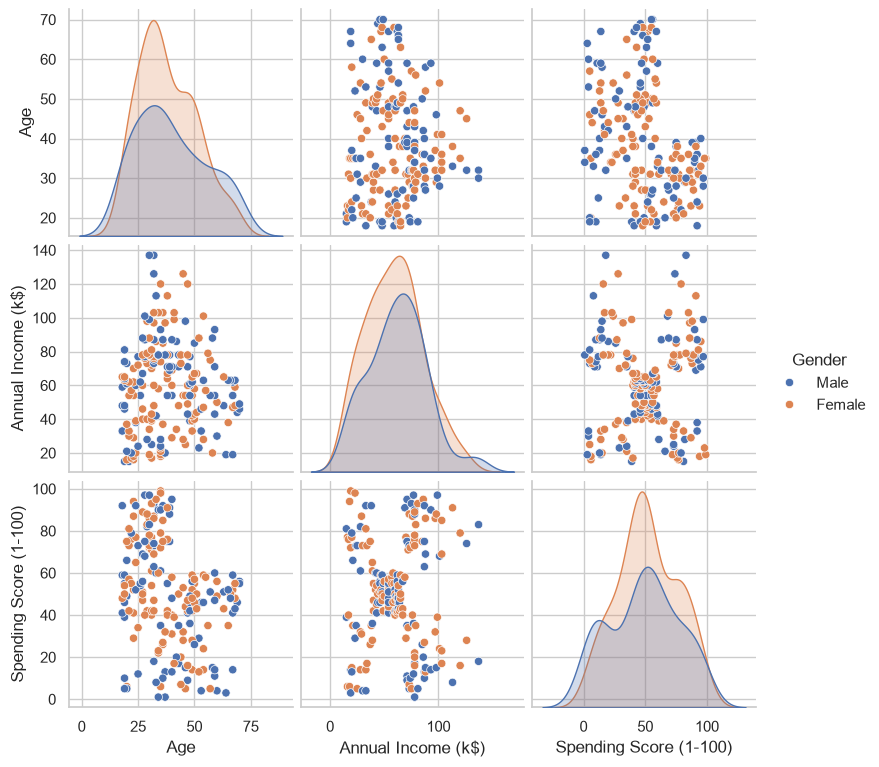

In [7]:
# Relaciones entre variables
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlación')
plt.show()

sns.pairplot(df, vars=num_cols, hue='Gender', diag_kind='kde', height=2.6)
plt.show()

### Preguntas – Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**

Las más adecuadas son **Ingreso Anual (k$)** y **Puntaje de Gasto (1-100)**, por tres razones:
- Juntas describen lo que le interesa al negocio: cuánto **puede** gastar el cliente (ingreso) y cuánto **gasta** realmente (puntaje).
- En el diagrama de dispersión ingreso vs. gasto se ven a simple vista **cinco nubes de puntos** separadas, una estructura que K-Means puede capturar.
- Con dos dimensiones los clusters se pueden graficar y explicar a un equipo de marketing.

`CustomerID` no aporta información y `Gender` es categórica, con distribuciones muy parecidas entre hombres y mujeres. `Age` se usa después para **describir** los grupos. Al final de la Parte 4 se compara el modelo con y sin `Age` para justificar esta elección.

**¿Se identifican valores atípicos?**

Prácticamente no. Con el criterio IQR, `Age` y `Spending Score` no tienen atípicos. En `Annual Income` solo aparecen **2 registros con 137 k$**, que superan apenas el límite superior (≈132 k$). Son valores plausibles (clientes de ingresos altos), no errores de captura, así que **se conservan**. Además, el dataset no tiene valores nulos ni duplicados.

**¿Qué tipo de relaciones se observan entre las variables?**

- **Ingreso vs. Gasto:** la correlación lineal es casi nula (r ≈ 0.01). No hay una relación lineal: ganar más no implica gastar más. Aun así, el diagrama de dispersión muestra una **relación no lineal por grupos** (cinco agrupaciones con forma de "X"), justo lo que la segmentación busca descubrir.
- **Edad vs. Gasto:** correlación negativa moderada (r ≈ -0.33). Los clientes jóvenes tienden a tener puntajes de gasto más altos y los mayores de 40 rara vez superan 60 puntos.
- **Edad vs. Ingreso:** sin relación (r ≈ -0.01).
- **Género:** las distribuciones de hombres y mujeres casi se superponen (hay 112 mujeres y 88 hombres), por lo que el género no diferencia grupos.

## Parte 2 – Preprocesamiento

In [8]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Media después de escalar:", X_scaled.mean(axis=0).round(4))
print("Desviación estándar después de escalar:", X_scaled.std(axis=0).round(4))
print("\nPrimeras 5 filas escaladas:")
print(X_scaled[:5])

Media después de escalar: [-0. -0.]
Desviación estándar después de escalar: [1. 1.]

Primeras 5 filas escaladas:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


### Pregunta – Parte 2

**¿Por qué es necesario escalar las variables en el algoritmo K-Means?**

K-Means asigna cada punto al centroide más cercano usando la **distancia euclidiana**, y esa distancia depende de las unidades de cada variable. Si una variable tiene un rango numérico mucho mayor que otra, **domina el cálculo de la distancia** y los clusters terminan formándose casi solo con ella. Por ejemplo, si se agregara un ingreso en pesos (millones) junto al puntaje de gasto (1 a 100), el gasto prácticamente no contaría.

`StandardScaler` transforma cada variable a **media 0 y desviación estándar 1**, con z = (x − μ) / σ. Así todas las variables contribuyen por igual a la distancia y los grupos reflejan la estructura real de los datos y no la escala en que se midieron. También mejora la convergencia del algoritmo.

> Nota: el mismo `scaler` ajustado aquí se usa luego para transformar a los clientes nuevos antes de clasificarlos (en el notebook y en la app de Streamlit).

## Parte 3 – Método del Codo

K =  1  WCSS =  400.00
K =  2  WCSS =  269.69
K =  3  WCSS =  157.70
K =  4  WCSS =  108.92
K =  5  WCSS =   65.57
K =  6  WCSS =   55.06
K =  7  WCSS =   44.86
K =  8  WCSS =   37.23
K =  9  WCSS =   32.39
K = 10  WCSS =   29.98


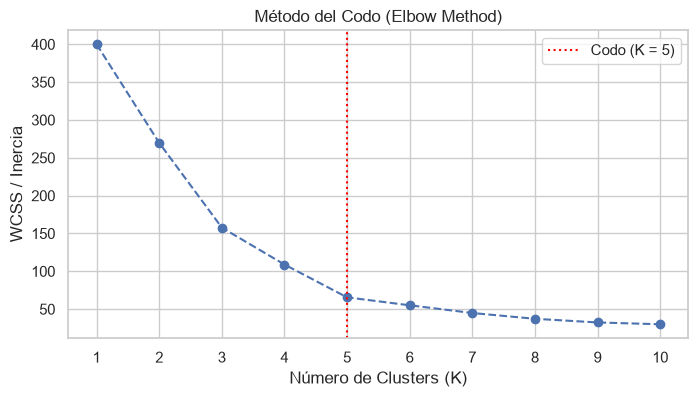

In [9]:
k_range = range(1, 11)
wcss = []
for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

for k, w in zip(k_range, wcss):
    print(f"K = {k:2d}  WCSS = {w:7.2f}")

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='b')
plt.axvline(5, color='red', linestyle=':', label='Codo (K = 5)')
plt.title('Método del Codo (Elbow Method)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('WCSS / Inercia')
plt.xticks(list(k_range))
plt.legend()
plt.show()

In [10]:
# Reducción de la inercia al pasar de K-1 a K
reduccion = pd.DataFrame({
    'K': list(k_range)[1:],
    'Reducción WCSS': -np.diff(wcss),
    'Reducción %': (-np.diff(wcss) / np.array(wcss[:-1]) * 100)
}).round(2)
reduccion

,K,Reducción WCSS,Reducción %
0,2,130.31,32.58
1,3,111.99,41.52
2,4,48.78,30.93
3,5,43.35,39.80
4,6,10.51,16.03
5,7,10.19,18.51
6,8,7.64,17.02
7,9,4.84,12.99
8,10,2.41,7.44


### Preguntas – Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**

La WCSS (inercia) es la **suma de las distancias al cuadrado de cada punto a su centroide**. Si es cercana a cero, los puntos están muy pegados a su centroide: los clusters son **compactos y homogéneos** por dentro, y cada centroide representa bien a los clientes de su grupo.

Hay una salvedad: la WCSS **siempre disminuye al aumentar K**. Si K fuera igual al número de clientes (200), la WCSS sería exactamente 0, porque cada punto sería su propio centroide, pero el modelo no serviría (sobreajuste). Por eso no se busca la WCSS mínima, sino el punto donde agregar más clusters deja de mejorarla de forma importante.

**¿Cómo se identifica el punto óptimo de K?**

Se busca el **"codo" de la curva**, el valor de K a partir del cual la pendiente se suaviza y la WCSS deja de caer bruscamente. En este dataset:

| Paso | Reducción de WCSS |
|---|---|
| K 3 → 4 | ≈ 49 |
| K 4 → 5 | ≈ 43 |
| **K 5 → 6** | **≈ 10** |
| K 6 → 7 | ≈ 10 |

Hasta K = 5 cada cluster adicional reduce mucho la inercia. Desde K = 6 la ganancia es marginal. **El codo está en K = 5**, que además coincide con las cinco nubes que se ven en el diagrama de dispersión.

## Parte 4 – Coeficiente de Silueta

K =  2  Silueta = 0.3213
K =  3  Silueta = 0.4666
K =  4  Silueta = 0.4939
K =  5  Silueta = 0.5547
K =  6  Silueta = 0.5399


K =  7  Silueta = 0.5281
K =  8  Silueta = 0.4552
K =  9  Silueta = 0.4571
K = 10  Silueta = 0.4432

Mejor K según silueta: 5 (0.5547)


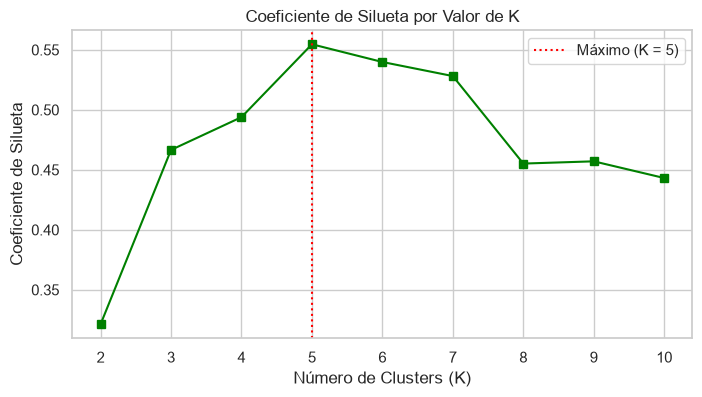

In [11]:
k_range_sil = range(2, 11)
silhouette_scores = []
for k in k_range_sil:
    labels = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10).fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"K = {k:2d}  Silueta = {score:.4f}")

k_best = list(k_range_sil)[int(np.argmax(silhouette_scores))]
print(f"\nMejor K según silueta: {k_best} ({max(silhouette_scores):.4f})")

plt.figure(figsize=(8, 4))
plt.plot(k_range_sil, silhouette_scores, marker='s', color='green')
plt.axvline(k_best, color='red', linestyle=':', label=f'Máximo (K = {k_best})')
plt.title('Coeficiente de Silueta por Valor de K')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Coeficiente de Silueta')
plt.xticks(list(k_range_sil))
plt.legend()
plt.show()

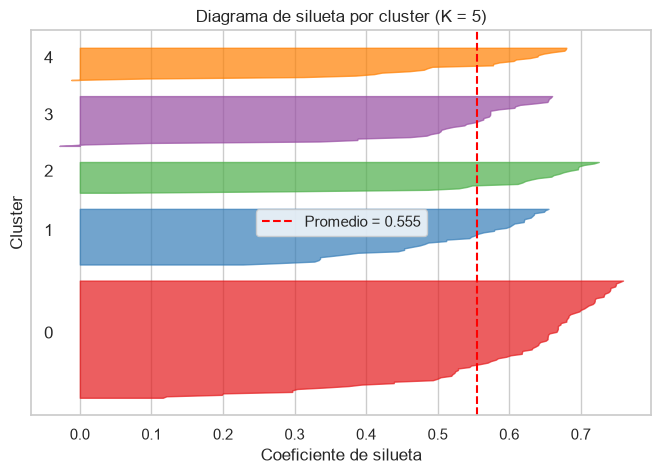

Observaciones con silueta negativa: 2 de 200


In [12]:
# Diagrama de silueta por observación para K = 5
labels_5 = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10).fit_predict(X_scaled)
sil_vals = silhouette_samples(X_scaled, labels_5)
avg = sil_vals.mean()

fig, ax = plt.subplots(figsize=(8, 5))
y_low = 10
for c in range(5):
    vals = np.sort(sil_vals[labels_5 == c])
    y_up = y_low + len(vals)
    ax.fill_betweenx(np.arange(y_low, y_up), 0, vals, alpha=0.7, color=plt.cm.Set1(c))
    ax.text(-0.05, y_low + len(vals) / 2, str(c))
    y_low = y_up + 10
ax.axvline(avg, color='red', linestyle='--', label=f'Promedio = {avg:.3f}')
ax.set_title('Diagrama de silueta por cluster (K = 5)')
ax.set_xlabel('Coeficiente de silueta')
ax.set_ylabel('Cluster')
ax.set_yticks([])
ax.legend()
plt.show()

print(f"Observaciones con silueta negativa: {(sil_vals < 0).sum()} de {len(sil_vals)}")

In [13]:
# Justificación de las variables: comparar con y sin la edad
X3 = StandardScaler().fit_transform(df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']])
comparacion = []
for k in range(2, 11):
    s2 = silhouette_score(X_scaled, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled))
    s3 = silhouette_score(X3, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X3))
    comparacion.append((k, round(s2, 4), round(s3, 4)))
pd.DataFrame(comparacion, columns=['K', 'Ingreso + Gasto', 'Edad + Ingreso + Gasto'])

,K,Ingreso + Gasto,Edad + Ingreso + Gasto
0,2,0.3213,0.3355
1,3,0.4666,0.3578
2,4,0.4939,0.4040
3,5,0.5547,0.4166
4,6,0.5399,0.4284
5,7,0.5281,0.4172
6,8,0.4552,0.4082
7,9,0.4571,0.4177
8,10,0.4432,0.4066


### Preguntas – Parte 4

**¿Qué mide el coeficiente de silueta?**

Mide **qué tan bien asignada está cada observación a su cluster**, comparando cohesión y separación. Para cada punto *i*:
- **a(i):** distancia promedio a los puntos de **su propio** cluster (cohesión).
- **b(i):** distancia promedio a los puntos del **cluster vecino más cercano** (separación).

s(i) = (b(i) − a(i)) / max(a(i), b(i)), con valores entre **−1 y 1**. El coeficiente del modelo es el promedio de s(i) sobre todos los puntos. A diferencia de la WCSS, la silueta **no mejora automáticamente al aumentar K**, por eso sirve para elegir K.

**¿Qué significa un valor cercano a 1?**

Que el punto está mucho más cerca de los miembros de su cluster que de los del cluster vecino (a(i) ≪ b(i)). Los clusters son **compactos y están bien separados**, y la asignación es clara.

**¿Qué implica un valor cercano a 0 o negativo?**

- **Cercano a 0:** el punto está en la **frontera entre dos clusters** (a(i) ≈ b(i)). La asignación es ambigua y los grupos se solapan.
- **Negativo:** el punto está más cerca, en promedio, de otro cluster que del suyo (a(i) > b(i)). Probablemente está **mal asignado**, o el valor de K o el algoritmo no son adecuados para esos datos.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**

**Sí, coinciden en K = 5.**
- El **método del codo** muestra el cambio de pendiente en K = 5: la reducción de WCSS pasa de ≈43 (4→5) a ≈10 (5→6).
- El **coeficiente de silueta** alcanza su **máximo en K = 5 (≈ 0.555)**. Con K = 6 baja a ≈ 0.540 y desde K = 8 cae por debajo de 0.46.

Que dos criterios distintos (uno de compactación y otro de cohesión frente a separación) señalen el mismo K da confianza en la elección. En el diagrama de silueta, los cinco clusters superan o se acercan al promedio y casi no hay observaciones con silueta negativa, lo que confirma que los grupos están bien definidos.

Sobre las variables: al agregar la **edad**, la silueta máxima baja de forma notable (tabla anterior). Eso confirma la respuesta de la Parte 1: **Ingreso + Gasto** produce grupos más separados, y la edad se usa mejor para describirlos.

## Parte 5 – Modelo K-Means

In [14]:
k_optimo = 5
kmeans_final = KMeans(n_clusters=k_optimo, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

centroids_scaled = kmeans_final.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)
centroids_df = pd.DataFrame(centroids_original, columns=features).round(2)
centroids_df.index.name = 'Cluster'
print(f"Silueta del modelo final: {silhouette_score(X_scaled, df['Cluster']):.4f}")
print("\n--- Centroides (valores reales) ---")
centroids_df

Silueta del modelo final: 0.5547

--- Centroides (valores reales) ---


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


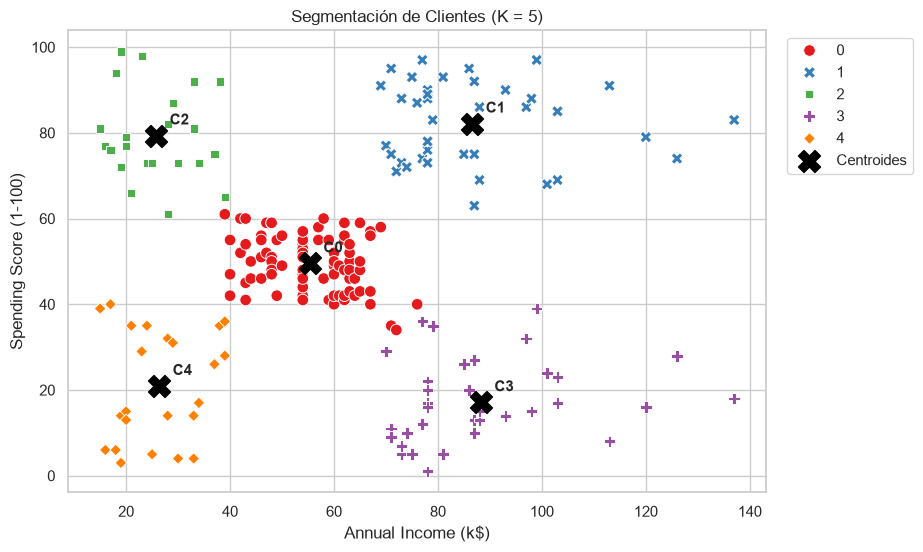

In [15]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster', palette='Set1', s=70, style='Cluster')
plt.scatter(centroids_original[:, 0], centroids_original[:, 1], s=250, c='black', marker='X', label='Centroides')
for i, (x, y) in enumerate(centroids_original):
    plt.annotate(f'C{i}', (x, y), textcoords='offset points', xytext=(10, 8), fontsize=11, weight='bold')
plt.title(f'Segmentación de Clientes (K = {k_optimo})')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

In [16]:
# Caracterización completa de cada cluster
resumen = df.groupby('Cluster').agg(
    Clientes=('CustomerID', 'count'),
    Edad_media=('Age', 'mean'),
    Ingreso_medio=('Annual Income (k$)', 'mean'),
    Gasto_medio=('Spending Score (1-100)', 'mean'),
    Pct_mujeres=('Gender', lambda s: (s == 'Female').mean() * 100),
).round(1)
resumen['Pct_clientes'] = (resumen['Clientes'] / len(df) * 100).round(1)
resumen

,Clientes,Edad_media,Ingreso_medio,Gasto_medio,Pct_mujeres,Pct_clientes
Cluster,,,,,,
0,81,42.7,55.3,49.5,59.3,40.5
1,39,32.7,86.5,82.1,53.8,19.5
2,22,25.3,25.7,79.4,59.1,11.0
3,35,41.1,88.2,17.1,45.7,17.5
4,23,45.2,26.3,20.9,60.9,11.5


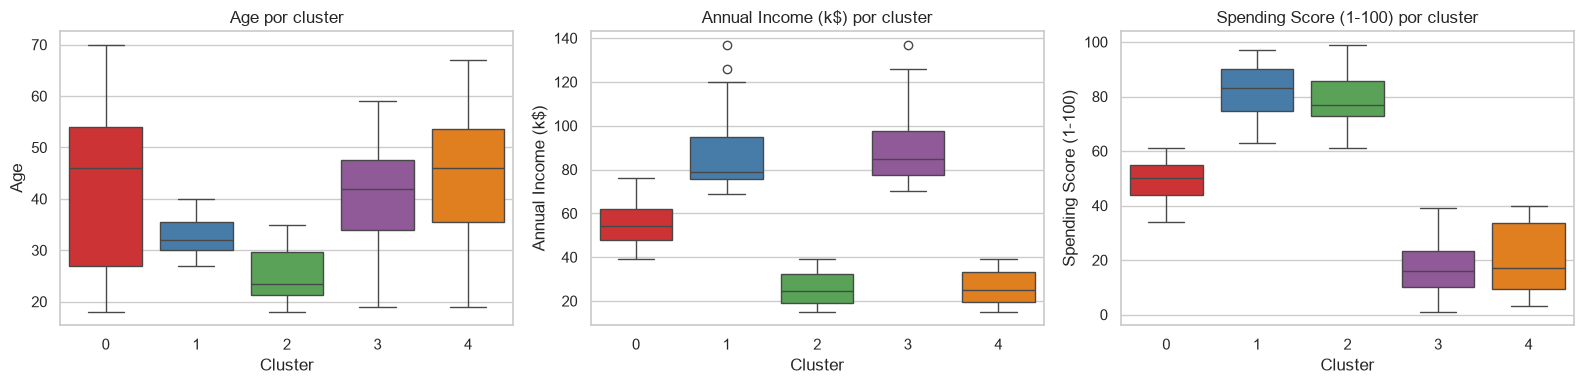

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='Cluster', y=col, hue='Cluster', palette='Set1', legend=False, ax=ax)
    ax.set_title(f'{col} por cluster')
plt.tight_layout()
plt.show()

### Preguntas – Parte 5

> Los números de cluster (0–4) dependen de la inicialización y de la versión de scikit-learn. Por eso la interpretación se hace por la **posición de los centroides** (ingreso y gasto), no por el número. Las cifras son las de la tabla de caracterización de arriba.

**¿Qué representa cada cluster?**

Cada cluster es un **grupo de clientes con un comportamiento de compra parecido**, y su centroide es el "cliente típico" del grupo:

| Grupo | Centroide aprox. (Ingreso, Gasto) | Tamaño | Edad media | Descripción |
|---|---|---|---|---|
| Ingreso alto – Gasto alto | (87 k$, 82) | ≈39 (19.5 %) | ≈33 | Ganan mucho y gastan mucho. |
| Ingreso alto – Gasto bajo | (88 k$, 17) | ≈35 (17.5 %) | ≈41 | Tienen capacidad de compra pero gastan poco en el centro comercial. |
| Ingreso medio – Gasto medio | (55 k$, 50) | ≈81 (40.5 %) | ≈43 | El grupo más grande, el cliente "típico". |
| Ingreso bajo – Gasto alto | (26 k$, 79) | ≈22 (11 %) | ≈25 | Jóvenes que gastan por encima de su ingreso. |
| Ingreso bajo – Gasto bajo | (26 k$, 21) | ≈23 (11.5 %) | ≈45 | Compran poco y tienen poca capacidad de compra. |

**¿Qué diferencias existen entre los grupos obtenidos?**

- **Ingreso:** se distinguen tres niveles (≈26, ≈55 y ≈87 k$). Los grupos de ingreso alto y bajo se dividen a su vez según el gasto.
- **Gasto:** entre grupos con **el mismo ingreso** el puntaje de gasto cambia por completo (≈17 frente a ≈82 en ingreso alto). Confirma que el ingreso por sí solo no explica el gasto (correlación ≈ 0).
- **Edad:** no se usó para entrenar el modelo, pero sí diferencia a los grupos. Los de **gasto alto son los más jóvenes** (≈25 y ≈33 años) y los de **gasto bajo son mayores** (≈41–45 años), en línea con la correlación negativa edad-gasto de la Parte 1.
- **Tamaño:** el grupo medio concentra cerca del 40 % de los clientes y los grupos de ingreso bajo son los más pequeños (≈11 % cada uno).
- **Género:** la proporción de mujeres va de ≈46 % a ≈61 % entre grupos, sin un patrón asociado al ingreso o al gasto, así que no es un factor diferenciador.

## Parte 6 – Interpretación de Negocio

In [18]:
def asignar_perfil(ingreso_z, gasto_z, umbral=0.5):
    """Asigna un perfil de negocio a partir del centroide escalado (z-scores)."""
    alto_ing, bajo_ing = ingreso_z > umbral, ingreso_z < -umbral
    alto_gas, bajo_gas = gasto_z > umbral, gasto_z < -umbral
    if alto_ing and alto_gas:
        return 'Alto valor (VIP)'
    if alto_ing and bajo_gas:
        return 'Con potencial (alto ingreso, bajo gasto)'
    if bajo_ing and alto_gas:
        return 'Impulsivos (bajo ingreso, alto gasto)'
    if bajo_ing and bajo_gas:
        return 'Bajo valor'
    return 'Promedio'

# El nombre se asigna según la posición del centroide y no según el número de cluster
cluster_names = {i: asignar_perfil(*c) for i, c in enumerate(centroids_scaled)}
for i, nombre in cluster_names.items():
    ing, gas = centroids_original[i]
    print(f"Cluster {i}: {nombre:45s} (Ingreso ≈ {ing:.1f} k$, Gasto ≈ {gas:.1f})")

df['Perfil_Negocio'] = df['Cluster'].map(cluster_names)

Cluster 0: Promedio                                      (Ingreso ≈ 55.3 k$, Gasto ≈ 49.5)
Cluster 1: Alto valor (VIP)                              (Ingreso ≈ 86.5 k$, Gasto ≈ 82.1)
Cluster 2: Impulsivos (bajo ingreso, alto gasto)         (Ingreso ≈ 25.7 k$, Gasto ≈ 79.4)
Cluster 3: Con potencial (alto ingreso, bajo gasto)      (Ingreso ≈ 88.2 k$, Gasto ≈ 17.1)
Cluster 4: Bajo valor                                    (Ingreso ≈ 26.3 k$, Gasto ≈ 20.9)


In [19]:
resumen_perfiles = df.groupby('Perfil_Negocio').agg(
    Clientes=('CustomerID', 'count'),
    Edad_media=('Age', 'mean'),
    Ingreso_medio=('Annual Income (k$)', 'mean'),
    Gasto_medio=('Spending Score (1-100)', 'mean'),
).round(1).sort_values('Ingreso_medio', ascending=False)
resumen_perfiles

,Clientes,Edad_media,Ingreso_medio,Gasto_medio
Perfil_Negocio,,,,
"Con potencial (alto ingreso, bajo gasto)",35,41.1,88.2,17.1
Alto valor (VIP),39,32.7,86.5,82.1
Promedio,81,42.7,55.3,49.5
Bajo valor,23,45.2,26.3,20.9
"Impulsivos (bajo ingreso, alto gasto)",22,25.3,25.7,79.4


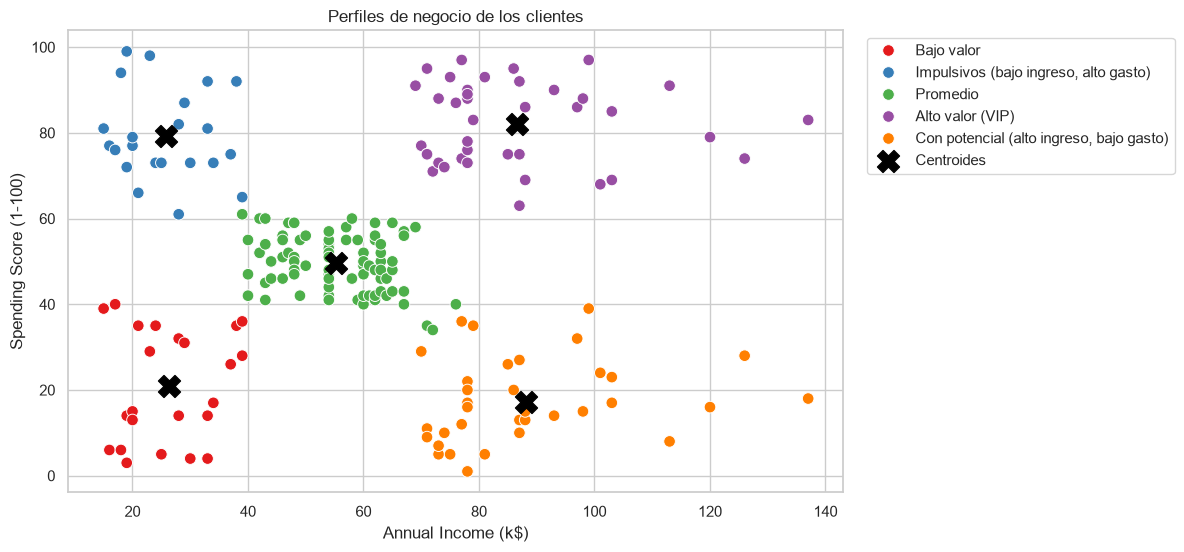

In [20]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Perfil_Negocio', palette='Set1', s=70)
plt.scatter(centroids_original[:, 0], centroids_original[:, 1], s=250, c='black', marker='X', label='Centroides')
plt.title('Perfiles de negocio de los clientes')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

In [21]:
# Ejemplo: clasificar un cliente nuevo con el modelo entrenado
nuevo = pd.DataFrame([[90, 20]], columns=features)  # 90 k$ de ingreso y puntaje de gasto 20
cluster_nuevo = kmeans_final.predict(scaler.transform(nuevo.values))[0]
print(f"El nuevo cliente pertenece al cluster {cluster_nuevo}: {cluster_names[cluster_nuevo]}")

El nuevo cliente pertenece al cluster 3: Con potencial (alto ingreso, bajo gasto)


### Clasificación de perfiles

| Perfil | Centroide (Ingreso, Gasto) | Justificación |
|---|---|---|
| **Clientes de alto valor (VIP)** | (87, 82) | Mayor ingreso y mayor gasto. Son los que más aportan a la facturación. |
| **Clientes promedio** | (55, 50) | Valores medios en ambas variables. Es el grupo más numeroso. |
| **Clientes de bajo valor** | (26, 21) | Bajo ingreso y bajo gasto. Aportan poco y tienen poco margen para crecer. |
| **Clientes con potencial** | (88, 17) | Tienen **alto poder adquisitivo** pero hoy gastan poco: el gasto que todavía no se capta. |
| *Impulsivos (subperfil)* | (26, 79) | Gastan mucho para su ingreso. Hoy son valiosos, pero su gasto es frágil porque está limitado por el ingreso. |

Con K = 5 sale un quinto grupo que no encaja exactamente en las cuatro categorías del taller. Se nombra como subperfil **"Impulsivos"**, que por su comportamiento está más cerca de los de alto valor (gasto alto) que de los de bajo valor.

### Preguntas – Parte 6

**¿Qué estrategias de marketing se podrían aplicar a cada grupo?**

- **Alto valor (VIP):** **fidelización y retención**. Programa de lealtad premium con beneficios exclusivos, preventas, atención personalizada, eventos privados y productos de gama alta. El objetivo es que no se vayan a la competencia y aumenten aún más su frecuencia.
- **Promedio:** **aumentar el ticket promedio**. Venta cruzada (cross-selling) y venta adicional (up-selling), combos, programa de puntos por niveles para subirlos hacia VIP, y campañas estacionales masivas (por ser el grupo más grande, son los que más rinden en volumen).
- **Bajo valor:** **eficiencia en costos**. Comunicación de bajo costo (correo, redes), promociones de precio, descuentos por volumen y temporadas de liquidación. No conviene invertir mucho presupuesto de adquisición en ellos.
- **Con potencial (alto ingreso, bajo gasto):** **activación y conversión**. Investigar por qué no compran (encuestas, análisis de satisfacción). Ofrecer experiencias de calidad y conveniencia (marcas premium, servicios como personal shopper o parqueadero preferencial) y ofertas personalizadas basadas en valor, no en descuento. Como la mayoría tiene alrededor de 40 años, conviene orientar la comunicación a calidad, familia y practicidad.
- **Impulsivos (bajo ingreso, alto gasto):** **mantener el gasto de forma sostenible**. Marketing en redes sociales y con influenciadores (es el grupo más joven, ≈25 años), promociones flash, pagos a plazos o "compra ahora, paga después", y marcas de moda asequibles. Conviene cuidar el riesgo de crédito.

**¿Qué segmento representa mayor oportunidad de crecimiento?**

El segmento **"Con potencial" (alto ingreso, bajo gasto)**, por estas razones:
1. Tiene **el ingreso promedio más alto del dataset (≈88 k$)**, igual o mayor que el de los VIP, pero su puntaje de gasto es apenas ≈17. Es la **mayor brecha entre capacidad de compra y gasto real**.
2. Es un grupo de buen tamaño (≈35 clientes, 17.5 %).
3. Los VIP ya gastan cerca del máximo y los Impulsivos están limitados por su ingreso, así que el crecimiento de esos grupos tiene techo. En cambio, **cada punto que suba el gasto de los clientes "Con potencial" se traduce en más ventas**, porque tienen con qué pagar.

Si se lograra llevar a este grupo a un gasto similar al de los VIP, el centro comercial captaría el gasto que hoy esos clientes destinan a otros lugares. En segundo lugar, el segmento **Promedio** ofrece oportunidad por **volumen**: pequeños aumentos en el ticket de 81 clientes tienen un impacto agregado importante.

## Parte 7 – Despliegue con Streamlit

La aplicación interactiva está en `app.py` y permite:
- Visualizar el **método del codo** y el **coeficiente de silueta**.
- Mostrar los **clusters generados**, con perfiles de negocio, para el K que elija el usuario.
- **Ingresar un nuevo cliente** (ingreso anual y puntaje de gasto).
- **Clasificarlo automáticamente** en un cluster y mostrar su perfil y la estrategia recomendada.

Para ejecutarla localmente:
```bash
pip install -r requirements.txt
streamlit run app.py
```
Aplicación desplegada en Streamlit Community Cloud: https://laboratoriomineriadatos-g823mjbeecj3xufmuuxfjy.streamlit.app/

## Conclusiones

1. Las variables **Ingreso Anual** y **Puntaje de Gasto**, escaladas con `StandardScaler`, son las que producen la segmentación más clara.
2. El **método del codo** y el **coeficiente de silueta** coinciden en que **K = 5** es el número óptimo de clusters (silueta ≈ 0.555).
3. Los cinco grupos se traducen en perfiles de negocio accionables: **Alto valor, Promedio, Bajo valor, Con potencial e Impulsivos**.
4. La mayor oportunidad de crecimiento está en los clientes **Con potencial** (alto ingreso, bajo gasto).
5. El modelo se despliega en una aplicación de **Streamlit** que clasifica nuevos clientes en tiempo real.